PART 1 - Ordinal/label encoding

In [2]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder


df = pd.DataFrame({
    "Customer_ID": range(101, 113),
    "Satisfaction": [
        "Poor", "Good", "Average", "Excellent",
        "Poor", "Good", "Average", "Excellent",
        "Good", "Average", "Excellent", "Poor"
    ],
    "Purchase_Amount": [
        500, 1200, 800, 2500,
        400, 1500, 900, 3000,
        1800, 700, 2800, 350
    ],
    "Membership": [
        "Bronze", "Silver", "Bronze", "Gold",
        "Bronze", "Gold", "Silver", "Gold",
        "Silver", "Bronze", "Gold", "Silver"
    ]
})
encoder01 = OrdinalEncoder(
    categories=[["Poor", "Average", "Good", "Excellent"]])

df[["Satisfaction"]] = encoder01.fit_transform(df[["Satisfaction"]])
df


,Customer_ID,Satisfaction,Purchase_Amount,Membership
0,101,0.0,500,Bronze
1,102,2.0,1200,Silver
2,103,1.0,800,Bronze
3,104,3.0,2500,Gold
4,105,0.0,400,Bronze
5,106,2.0,1500,Gold
6,107,1.0,900,Silver
7,108,3.0,3000,Gold
8,109,2.0,1800,Silver
9,110,1.0,700,Bronze


In [3]:
membership_encoder = OrdinalEncoder(
    categories = [["Bronze", "Silver", "Gold"]]
)
df[["Membership"]] = membership_encoder.fit_transform(df[["Membership"]])
df

,Customer_ID,Satisfaction,Purchase_Amount,Membership
0,101,0.0,500,0.0
1,102,2.0,1200,1.0
2,103,1.0,800,0.0
3,104,3.0,2500,2.0
4,105,0.0,400,0.0
5,106,2.0,1500,2.0
6,107,1.0,900,1.0
7,108,3.0,3000,2.0
8,109,2.0,1800,1.0
9,110,1.0,700,0.0


In [4]:
df02 = pd.DataFrame({
    "Study_Level": [
        "Low", "Medium", "High", "Low", "High",
        "Medium", "High", "Low", "Medium", "High",
        "Low", "Medium"
    ],
    "City": [
        "Bhopal", "Delhi", "Mumbai", "Delhi",
        "Bhopal", "Mumbai", "Delhi", "Mumbai",
        "Bhopal", "Delhi", "Mumbai", "Bhopal"
    ],
    "Result": [
        "Fail", "Pass", "Pass", "Fail",
        "Pass", "Pass", "Pass", "Fail",
        "Pass", "Pass", "Fail", "Pass"
    ]
})

encoder02 = OrdinalEncoder(
    categories=[["Low", "Medium", "High"]]
)
df02[["Study_Level"]] = encoder02.fit_transform(df02[["Study_Level"]])
df02

,Study_Level,City,Result
0,0.0,Bhopal,Fail
1,1.0,Delhi,Pass
2,2.0,Mumbai,Pass
3,0.0,Delhi,Fail
4,2.0,Bhopal,Pass
5,1.0,Mumbai,Pass
6,2.0,Delhi,Pass
7,0.0,Mumbai,Fail
8,1.0,Bhopal,Pass
9,2.0,Delhi,Pass


In [5]:
label_encoder01 = LabelEncoder()
df02["Result_Encoded"] = label_encoder01.fit_transform(df02["Result"])
df02

,Study_Level,City,Result,Result_Encoded
0,0.0,Bhopal,Fail,0
1,1.0,Delhi,Pass,1
2,2.0,Mumbai,Pass,1
3,0.0,Delhi,Fail,0
4,2.0,Bhopal,Pass,1
5,1.0,Mumbai,Pass,1
6,2.0,Delhi,Pass,1
7,0.0,Mumbai,Fail,0
8,1.0,Bhopal,Pass,1
9,2.0,Delhi,Pass,1


In [6]:
df03 = pd.DataFrame({
    "Size": [
        "Small", "Medium", "Large", "Medium",
        "Small", "Large", "XL", "Medium",
        "XL", "Small", "Large", "XL"
    ],
    "Color": [
        "Red", "Blue", "Green", "Red",
        "Green", "Blue", "Red", "Green",
        "Blue", "Red", "Blue", "Green"
    ],
    "Satisfaction": [
        "Poor", "Good", "Average", "Excellent",
        "Average", "Good", "Excellent", "Poor",
        "Good", "Average", "Excellent", "Good"
    ],
    "Order_Value": [
        500, 900, 1500, 1100,
        650, 1700, 2200, 700,
        2100, 550, 1600, 2300
    ]
})

encoder03 = OrdinalEncoder(
    categories=[
        ["Small", "Medium", "Large", "XL"],
        ["Poor", "Average", "Good", "Excellent"]
    ]
)

df03[["Size", "Satisfaction"]] = encoder03.fit_transform(
    df03[["Size", "Satisfaction"]]
)
df03

,Size,Color,Satisfaction,Order_Value
0,0.0,Red,0.0,500
1,1.0,Blue,2.0,900
2,2.0,Green,1.0,1500
3,1.0,Red,3.0,1100
4,0.0,Green,1.0,650
5,2.0,Blue,2.0,1700
6,3.0,Red,3.0,2200
7,1.0,Green,0.0,700
8,3.0,Blue,2.0,2100
9,0.0,Red,1.0,550


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

df03 = pd.DataFrame({
    "Size": [
        "Small", "Medium", "Large", "Medium",
        "Small", "Large", "XL", "Medium",
        "XL", "Small", "Large", "XL"
    ],
    "Color": [
        "Red", "Blue", "Green", "Red",
        "Green", "Blue", "Red", "Green",
        "Blue", "Red", "Blue", "Green"
    ],
    "Satisfaction": [
        "Poor", "Good", "Average", "Excellent",
        "Average", "Good", "Excellent", "Poor",
        "Good", "Average", "Excellent", "Good"
    ],
    "Order_Value": [
        500, 900, 1500, 1100,
        650, 1700, 2200, 700,
        2100, 550, 1600, 2300
    ]
})

preprocessor = preprocessor = ColumnTransformer(
    transformers=[
        ("ordinal",
            OrdinalEncoder(categories=[
                ["Small", "Medium", "Large", "XL"],
                ["Poor", "Average", "Good", "Excellent"]]), ["Size", "Satisfaction"]),
        ("onehot",
            OneHotEncoder(),
            ["Color"])], remainder="passthrough")
encoded_data = preprocessor.fit_transform(df03)
column_names = preprocessor.get_feature_names_out()
encoded_df03 = encoded_df = pd.DataFrame(
    encoded_data,
    columns=column_names
)
encoded_df03


,ordinal__Size,ordinal__Satisfaction,onehot__Color_Blue,onehot__Color_Green,onehot__Color_Red,remainder__Order_Value
0,0.0,0.0,0.0,0.0,1.0,500.0
1,1.0,2.0,1.0,0.0,0.0,900.0
2,2.0,1.0,0.0,1.0,0.0,1500.0
3,1.0,3.0,0.0,0.0,1.0,1100.0
4,0.0,1.0,0.0,1.0,0.0,650.0
5,2.0,2.0,1.0,0.0,0.0,1700.0
6,3.0,3.0,0.0,0.0,1.0,2200.0
7,1.0,0.0,0.0,1.0,0.0,700.0
8,3.0,2.0,1.0,0.0,0.0,2100.0
9,0.0,1.0,0.0,0.0,1.0,550.0


PART 2 - One-Hot Encoding; high-cardinality caution

In [8]:
from sklearn.preprocessing import OneHotEncoder

df = pd.DataFrame({
    "Customer_ID": range(101, 113),
    "City": [
        "Bhopal", "Delhi", "Mumbai", "Bhopal",
        "Delhi", "Pune", "Mumbai", "Pune",
        "Bhopal", "Delhi", "Pune", "Mumbai"
    ],
    "Payment_Method": [
        "UPI", "Cash", "Card", "UPI",
        "Card", "Cash", "UPI", "Card",
        "Cash", "UPI", "Card", "Cash"
    ],
    "Purchase_Amount": [
        500, 1200, 800, 1500, 700, 900,
        1800, 1100, 600, 1300, 950, 2000
    ]
})

categorical_columns = ["City", "Payment_Method"]

encoder04 = OneHotEncoder(drop='first',sparse_output=False, dtype=int)

encoded_data01 = encoder04.fit_transform(df[categorical_columns])

encoded_df = pd.DataFrame(
    encoded_data01,
    columns=encoder04.get_feature_names_out(categorical_columns),
    index=df.index)

df_encoded = pd.concat(
    [df.drop(columns=categorical_columns), encoded_df],
    axis=1)

print("Original DataFrame dimensions:", df.shape)
print("Encoded DataFrame dimensions:", df_encoded.shape)
df_encoded

Original DataFrame dimensions: (12, 4)
Encoded DataFrame dimensions: (12, 7)


,Customer_ID,Purchase_Amount,City_Delhi,City_Mumbai,City_Pune,Payment_Method_Cash,Payment_Method_UPI
0,101,500,0,0,0,0,1
1,102,1200,1,0,0,1,0
2,103,800,0,1,0,0,0
3,104,1500,0,0,0,0,1
4,105,700,1,0,0,0,0
5,106,900,0,0,1,1,0
6,107,1800,0,1,0,0,1
7,108,1100,0,0,1,0,0
8,109,600,0,0,0,1,0
9,110,1300,1,0,0,0,1


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df04 = pd.DataFrame({
    "Age": [22, 35, 28, 45, 31, 24, 40, 29, 38, 26, 33, 42],
    "City": [
        "Bhopal", "Delhi", "Mumbai", "Pune",
        "Delhi", "Bhopal", "Mumbai", "Pune",
        "Delhi", "Mumbai", "Bhopal", "Pune"
    ],
    "Browser": [
        "Chrome", "Firefox", "Safari", "Chrome",
        "Safari", "Firefox", "Chrome", "Safari",
        "Firefox", "Chrome", "Safari", "Firefox"
    ],
    "Purchase_Amount": [
        600, 1500, 900, 2200, 1300, 750,
        2000, 1100, 1800, 850, 1400, 2100
    ]
})

categorical_columns02 = ['City', 'Browser']

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop = 'first',handle_unknown="ignore"), categorical_columns02),
        ("age", "passthrough", ["Age"])],
         remainder="passthrough")

model01 = Pipeline(steps=[
    ("preprocessing", preprocessor)])

X_encoded = model01.fit_transform(df04)

feature_names = model01.named_steps[
    "preprocessing"
].get_feature_names_out()
model01


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Age','City','Browser','Purchase_Amount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('age', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transfo

PART 3 - FunctionTransformer; PowerTransformer

In [10]:
import numpy as np
from sklearn.preprocessing import FunctionTransformer

df = pd.DataFrame({
    "Customer_ID": range(1, 11),
    "Income": [15000, 18000, 22000, 25000, 30000,
               35000, 42000, 55000, 120000, 500000],
    "Monthly_Expenses": [8000, 9000, 11000, 12000, 15000,
                         17000, 20000, 25000, 45000, 180000]
})

transformer = FunctionTransformer(func=np.log1p, validate=False)

features_to_transform = ["Income", "Monthly_Expenses"]

df_transformed = df.copy()
df_transformed[features_to_transform] = transformer.transform(df[features_to_transform])

df_transformed


,Customer_ID,Income,Monthly_Expenses
0,1,9.615872,8.987322
1,2,9.798183,9.105091
2,3,9.998843,9.305741
3,4,10.126671,9.392745
4,5,10.308986,9.615872
5,6,10.463132,9.741027
6,7,10.645449,9.903538
7,8,10.915107,10.126671
8,9,11.695255,10.714440
9,10,13.122365,12.100718


In [11]:
df_comparison = pd.DataFrame({
    "Original Mean": df.mean(),
    "Transformed Mean": df_transformed.mean(),

    "Original Range": df.max() - df.min(),
    "Transformed Range": df_transformed.max() - df_transformed.min(),

    "Original Std": df.std(),
    "Transformed Std": df_transformed.std()
})

df_comparison

,Original Mean,Transformed Mean,Original Range,Transformed Range,Original Std,Transformed Std
Customer_ID,5.5,5.500000,9,9.000000,3.027650,3.027650
Income,86200.0,10.668986,485000,3.506493,148573.812557,1.049653
Monthly_Expenses,34200.0,9.899317,172000,3.113396,52363.685466,0.927312


In [12]:
from sklearn import pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LinearRegression

X = df[["Income"]]
y = df["Monthly_Expenses"]

model02 = Pipeline([
    ("log_transform", FunctionTransformer(func=np.log1p, validate=False)),
    ("regressor", LinearRegression())])

model02.fit(X,y)

monthly_expenses_pred = model02.predict(X)

print("Model Score:", model02.score(X, y))

df05 = pd.DataFrame(monthly_expenses_pred)
df05


Model Score: 0.8439171074993423


,0
0,-14062.484144
1,-5707.497205
2,3488.446767
3,9346.589293
4,17701.779895
5,24766.032975
6,33121.310863
7,45479.289282
8,81232.217359
9,146634.314914


In [13]:
df06 = pd.DataFrame({
    "Sales": [100, 150, 200, 250, 400, 600, 900, 1500, 3000, 8000],
    "Transaction_Count": [1, 2, 2, 3, 4, 5, 7, 10, 15, 30],
    "Discount_Percent": [0, 5, 10, 15, 20, 5, 10, 25, 30, 40],
    "Revenue": [120, 170, 230, 280, 450, 650, 950, 1600, 3200, 8500]
})

def convert_to_thousands(x):
    return x / 1000.0

sales_transformer = FunctionTransformer(convert_to_thousands)
sqrt_transformer = FunctionTransformer(np.sqrt)

df06['sales thousands'] = sales_transformer.transform(df06[['Sales']])
df06['Transaction Count Sqrt'] = sqrt_transformer.transform(df06[['Transaction_Count']])

df06[['Sales', 'sales thousands', "Transaction_Count","Transaction Count Sqrt"]]

,Sales,sales thousands,Transaction_Count,Transaction Count Sqrt
0,100,0.10,1,1.000000
1,150,0.15,2,1.414214
2,200,0.20,2,1.414214
3,250,0.25,3,1.732051
4,400,0.40,4,2.000000
5,600,0.60,5,2.236068
6,900,0.90,7,2.645751
7,1500,1.50,10,3.162278
8,3000,3.00,15,3.872983
9,8000,8.00,30,5.477226


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PowerTransformer

df07 = pd.DataFrame({
    "Annual_Income": [20000, 22000, 25000, 28000, 32000,
                      40000, 50000, 70000, 150000, 600000],
    "Loan_Amount": [5000, 7000, 9000, 12000, 15000,
                    20000, 30000, 50000, 100000, 400000],
    "Account_Balance": [-500, 0, 200, 500, 1000,
                        2500, 4000, 8000, 15000, 50000]
})

model03 = PowerTransformer(method="yeo-johnson")

df_transformed02 = pd.DataFrame(
    model03.fit_transform(df07),
    columns=df07.columns
)
df_transformed02



,Annual_Income,Loan_Amount,Account_Balance
0,-1.379800,-1.598540,-1.790811
1,-1.135075,-1.118793,-0.435484
2,-0.834195,-0.796072,-0.389377
3,-0.591466,-0.460345,-0.343830
4,-0.331735,-0.222567,-0.281733
5,0.046137,0.057434,-0.131388
6,0.363532,0.406495,-0.004242
7,0.748731,0.780375,0.286107
8,1.323458,1.190460,0.715134
9,1.790412,1.761553,2.375624


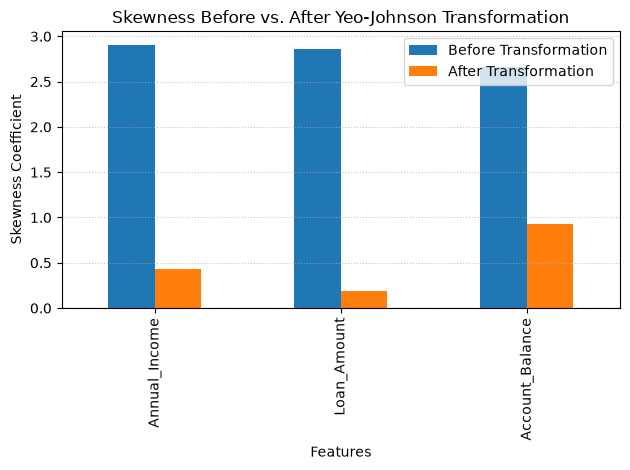

In [15]:
skew_before = df07.skew()
skew_after = df_transformed02.skew()

skew_comparison = pd.DataFrame({
    "Before Transformation": skew_before,
    "After Transformation": skew_after
})

ax = skew_comparison.plot(
    kind="bar")

plt.title("Skewness Before vs. After Yeo-Johnson Transformation")
plt.ylabel("Skewness Coefficient")
plt.xlabel("Features")
plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=0.8,)
plt.grid(axis="y", linestyle=":", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
df = pd.DataFrame({
    "Annual_Income": [20000, 22000, 25000, 28000, 32000,
                      40000, 50000, 70000, 150000, 600000],
    "Loan_Amount": [5000, 7000, 9000, 12000, 15000,
                    20000, 30000, 50000, 100000, 400000],
    "Account_Balance": [-500, 0, 200, 500, 1000,
                        2500, 4000, 8000, 15000, 50000]})

model04 = PowerTransformer(method="box-cox")

df_boxcox = df.copy()

df_boxcox[["Annual_Income", "Loan_Amount"]] = model04.fit_transform(
    df[["Annual_Income", "Loan_Amount"]])

df_boxcox

,Annual_Income,Loan_Amount,Account_Balance
0,-1.379808,-1.598572,-500
1,-1.135078,-1.118789,0
2,-0.834193,-0.796057,200
3,-0.591462,-0.460328,500
4,-0.331730,-0.222553,1000
5,0.046141,0.057442,2500
6,0.363535,0.406494,4000
7,0.748731,0.780365,8000
8,1.323454,1.190445,15000
9,1.790409,1.761555,50000


In [17]:
pt_boxcox = PowerTransformer(method="box-cox")
try:
    pt_boxcox.fit_transform(df[["Account_Balance"]])
except ValueError as e:
    print("Caught expected ValueError:",e)

Caught expected ValueError: The Box-Cox transformation can only be applied to strictly positive data


PART 4 - Missing-value strategies ,Mean/Median/Mode ,Simple-Imputer

In [18]:
df08 = pd.DataFrame({

"Age": [22, 25, np.nan, 30, 35, 100, np.nan, 28],

"Monthly_Income": [20000, 25000, 30000, np.nan, 35000, 500000, 28000, np.nan],

"City": ["Delhi", "Mumbai", "Delhi", np.nan, "Pune", "Delhi", np.nan, "Mumbai"],

"Purchase_Category": ["Electronics", "Clothing", np.nan,"Electronics", "Clothing", "Electronics", "Clothing", np.nan]})

missing_values = df08.isnull().sum()
print(missing_values)

df_stats = df08.copy()

df_mean = df08.copy()
df_mean['Age'] = df_mean['Age'].fillna(df_mean['Age'].mean())
df_mean['Monthly_Income'] = df_mean['Monthly_Income'].fillna(df_mean['Monthly_Income'].mean())

df_median = df08.copy()
df_median['Age'] = df_median['Age'].fillna(df_median['Age'].median())
df_median['Monthly_Income'] = df_median['Monthly_Income'].fillna(df_median['Monthly_Income'].median())

df_mode = df08.copy()
df_mode['City'] = df_mode['City'].fillna(df_mode['City'].mode())
df_mode['Purchase_Category'] = df_mode['Purchase_Category'].fillna(df_mode['Purchase_Category'].mode())
print("\n")
print("MEAN")
print(df_mean)
print("\n")
print("MEDIAN")
print(df_median)
print("\n")
print("MODE")
print(df_mode)

Age                  2
Monthly_Income       2
City                 2
Purchase_Category    2
dtype: int64


MEAN
     Age  Monthly_Income    City Purchase_Category
0   22.0    20000.000000   Delhi       Electronics
1   25.0    25000.000000  Mumbai          Clothing
2   40.0    30000.000000   Delhi               NaN
3   30.0   106333.333333     NaN       Electronics
4   35.0    35000.000000    Pune          Clothing
5  100.0   500000.000000   Delhi       Electronics
6   40.0    28000.000000     NaN          Clothing
7   28.0   106333.333333  Mumbai               NaN


MEDIAN
     Age  Monthly_Income    City Purchase_Category
0   22.0         20000.0   Delhi       Electronics
1   25.0         25000.0  Mumbai          Clothing
2   29.0         30000.0   Delhi               NaN
3   30.0         29000.0     NaN       Electronics
4   35.0         35000.0    Pune          Clothing
5  100.0        500000.0   Delhi       Electronics
6   29.0         28000.0     NaN          Clothing
7   28.0    

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

df09 = pd.DataFrame({
    "Patient_Age": [25, 32, np.nan, 45, 52, np.nan, 38, 60],
    "Blood_Sugar": [90, 110, 105, np.nan, 250, 130, np.nan, 115],
    "Blood_Group": ["A", "B", "O", np.nan, "A", "B", np.nan, "A"],
    "Treatment": ["Basic", np.nan, "Advanced", "Basic",
                  "Advanced", "Basic", np.nan, "Basic"]})

preprocessor = ColumnTransformer(
    transformers=[("imputed_age", SimpleImputer(strategy="mean"), ["Patient_Age"]),
        ("imputed_sugar", SimpleImputer(strategy="median"), ["Blood_Sugar"]),
        (("impute_categorical"), SimpleImputer(strategy="most_frequent"),["Blood_Group", "Treatment"])])

model05 = preprocessor.fit_transform(df09)

columns = ["Patient_Age", "Blood_Sugar", "Blood_Group", "Treatment"]
imputed_df09 = pd.DataFrame(model05, columns=columns)

print("Missing Values Count")
print(imputed_df09.isnull().sum())
imputed_df09

Missing Values Count
Patient_Age    0
Blood_Sugar    0
Blood_Group    0
Treatment      0
dtype: int64


,Patient_Age,Blood_Sugar,Blood_Group,Treatment
0,25.0,90.0,A,Basic
1,32.0,110.0,B,Basic
2,42.0,105.0,O,Advanced
3,45.0,112.5,A,Basic
4,52.0,250.0,A,Advanced
5,42.0,130.0,B,Basic
6,38.0,112.5,A,Basic
7,60.0,115.0,A,Basic


In [20]:
preprocessor01 = ColumnTransformer(
    transformers=[
        ("impute_numerical_constant",
            SimpleImputer(strategy="constant", fill_value=0),
            ["Patient_Age", "Blood_Sugar"]),
        ("impute_categorical_constant",
            SimpleImputer(strategy="constant", fill_value="Unknown"),
            ["Blood_Group", "Treatment"])])

model06 = preprocessor01.fit_transform(df09)

columns = ["Patient_Age", "Blood_Sugar", "Blood_Group", "Treatment"]
imputed_df09 = pd.DataFrame(model06, columns=columns)

print("Completed DataFrame (Constant Imputation)")
print(imputed_df09)

print("\n Missing Values Count")
print(imputed_df09.isnull().sum())

Completed DataFrame (Constant Imputation)
  Patient_Age Blood_Sugar Blood_Group Treatment
0        25.0        90.0           A     Basic
1        32.0       110.0           B   Unknown
2         0.0       105.0           O  Advanced
3        45.0         0.0     Unknown     Basic
4        52.0       250.0           A  Advanced
5         0.0       130.0           B     Basic
6        38.0         0.0     Unknown   Unknown
7        60.0       115.0           A     Basic

 Missing Values Count
Patient_Age    0
Blood_Sugar    0
Blood_Group    0
Treatment      0
dtype: int64


In [21]:
from sklearn.impute import SimpleImputer

df10 = pd.DataFrame({
    "Customer_ID": range(1, 11),
    "Annual_Spending": [12000, 15000, np.nan, 18000, 22000,
                        25000, 30000, np.nan, 900000, 20000],
    "Order_Count": [4, 5, 6, np.nan, 8, 7, 9, 10, 50, np.nan],
    "Membership": ["Silver", "Gold", "Silver", "Gold", np.nan,
                   "Silver", "Gold", np.nan, "Platinum", "Silver"]})

num_cols = ["Annual_Spending", "Order_Count"]

mean_imputer = SimpleImputer(strategy="mean")
df_mean = df10.copy()
df_mean[num_cols] = mean_imputer.fit_transform(df10[num_cols])

median_imputer = SimpleImputer(strategy="median")
df_median = df10.copy()
df_median[num_cols] = median_imputer.fit_transform(df10[num_cols])

print("Mean Imputed DataFrame")
print(df_mean)

print("Median Imputed DataFrame")
print(df_median)

Mean Imputed DataFrame
   Customer_ID  Annual_Spending  Order_Count Membership
0            1          12000.0        4.000     Silver
1            2          15000.0        5.000       Gold
2            3         130250.0        6.000     Silver
3            4          18000.0       12.375       Gold
4            5          22000.0        8.000        NaN
5            6          25000.0        7.000     Silver
6            7          30000.0        9.000       Gold
7            8         130250.0       10.000        NaN
8            9         900000.0       50.000   Platinum
9           10          20000.0       12.375     Silver
Median Imputed DataFrame
   Customer_ID  Annual_Spending  Order_Count Membership
0            1          12000.0          4.0     Silver
1            2          15000.0          5.0       Gold
2            3          21000.0          6.0     Silver
3            4          18000.0          7.5       Gold
4            5          22000.0          8.0        NaN


In [23]:
numeric_features = ["Annual_Spending", "Order_Count"]
categorical_features = ["Membership"]

numeric_transformer = Pipeline(
    steps=[
        ( "imputer",SimpleImputer(strategy="median"))])

categorical_transformer = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent"))])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)])

transformed_array = preprocessor.fit_transform(df10)

all_features = numeric_features + categorical_features
df_processed = pd.DataFrame(transformed_array, columns=all_features)

df_processed.insert(0, "Customer_ID", df10["Customer_ID"])

df_processed

,Customer_ID,Annual_Spending,Order_Count,Membership
0,1,12000.0,4.0,Silver
1,2,15000.0,5.0,Gold
2,3,21000.0,6.0,Silver
3,4,18000.0,7.5,Gold
4,5,22000.0,8.0,Silver
5,6,25000.0,7.0,Silver
6,7,30000.0,9.0,Gold
7,8,21000.0,10.0,Silver
8,9,900000.0,50.0,Platinum
9,10,20000.0,7.5,Silver
